## Single-column RCE model

This notebook contains the structure for your RCE model. There are key functions to complete and all visulizations are left to your design.

This RCE model will follow the Manabe and Strickler 1964 approach.

In [46]:
import numpy as np
import matplotlib.pyplot as plt

#### Main settings and parameters

In [47]:
# Experiment selection:
# 'convective_mode_variation' runs the sweep of equilibrium modes
# 'tau0_variation' runs a sweep of surface optical thickness values (tau0)
select_experiment = 'convective_mode_variation'

# Experiment-dependent settings:
convective_mode_sweep = ["radiative", "dry", "moist"] #, "dry", "moist"] # the three equilibrium modes to sweep over
tau0_sweep = [0.1, 1, 2, 4, 6] # surface optical depth values to sweep over

#### Parameters

In [48]:
# Physical constants
g = 9.81                  # m/s^2
Rd = 287.0                # J/(kg K)
Rv = 461.0                # J/(kg K)
cp = 1004.0               # J/(kg K)
Lv = 2.5e6                # J/kg
sigma = 5.670374419e-8    # Stefan-Boltzmann
CtoK = 273.15             # Celsius to Kelvin

# Model parameters
Nz = 60                   # number of atmospheric layers
p_surf = 100000.0         # Pa
p_top  = 5000.0           # Pa
dt = 1000.0               # time step (s)
max_iter = 50000          # maximum number of iterations
T0_init = 250.0           # initial isothermal temperature profile (K)

# Radiative transfer settings
S0 = 1361.0                     # solar constant (W/m2)
albedo = 0.3                    # planetary albedo
S_in = S0 * (1 - albedo) / 4.0  # incoming solar radiation at TOA (W/m2)
relh0 = 0.8                     # assumed constant relative humidity for moist convective mixing
tau0 = 4.0                      # optical thickness at surface (tau(p_surf) = tau0)
tau_n = 2.0                     # exponent for tau(p) = tau0 * (p/p0)^n
mu_bar = 0.6                    # diffusivity factor for conversion from I to F

#### Helper functions

##### Create vertical grid

In [49]:
'''
This function sets up the vertical grid and initial T-profile for the RCE model.

Its structure is as follows:

             TOP
        -------------------  p_edges[Nz] = p_top
             p_mid[Nz-1]     layer Nz-1
        -------------------  p_edges[Nz-1]
               ...
        -------------------  p_edges[2]
             p_mid[1]        layer 1
        -------------------  p_edges[1]
             p_mid[0]        layer 0
        -------------------  p_edges[0] = p_surf
            SURFACE

Index increases upward; pressure decreases upward.
Grid spacing is uniform in pressure.

Temperature is defined at layer midpoints.
Optical depth tau is defined at edges and decreases upward
(assuming tau0 > 0 and tau_n > 0).

For each layer k:
  p_mid[k] = 0.5 * (p_edges[k] + p_edges[k+1])
  dp[k]    = p_edges[k] - p_edges[k+1] > 0
  dtau[k]  = tau_edges[k] - tau_edges[k+1] > 0

'''
def get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init):

    # Vertical grid (pressure edges and midpoints)
    p_edges = np.linspace(p_surf, p_top, Nz+1)    # edges (Pa), bottom --> top
    p_mid = 0.5*(p_edges[:-1] + p_edges[1:])      # pressure at layer mid-points
    dp = p_edges[:-1] - p_edges[1:]               # dp of each layer (positive)

    # Optical depth at layer edges
    tau_edges = tau0 * (p_edges / p_surf)**tau_n
    dtau = tau_edges[:-1] - tau_edges[1:]

    # Initial isothermal temperature profile (defined at layer midpoints)
    T_init = np.repeat(T0_init, Nz) # K

    grid = {}
    grid['p_edges'] = p_edges
    grid['p_mid'] = p_mid
    grid['dp'] = dp
    grid['tau_edges'] = tau_edges
    grid['dtau'] = dtau
    grid['T_init'] = T_init

    return grid

##### Thermodynamic functions

In [50]:
# saturation vapor pressure (Magnus)
def es_sat(Tk):
    Tc = Tk - 273.15
    return 610.94 * np.exp(17.625 * Tc / (Tc + 243.04))

# saturation mixing ratio from saturation vapor pressure
def qsat(Tk, p):
    eps = Rd / Rv
    e_s = es_sat(Tk)
    return eps * e_s / (p - (1-eps)*e_s)

def moist_lapse_rate_K_per_m(DALR, Tk, p, RH=1.0):
    """
    Moist-adiabatic lapse rate with saturation mixing ratio scaled by a given RH.
    DALR input is the dry adiabatic lapse rate, provided either in K/m or K/Pa,
    which determines the units of the returned lapse rate.
    """
    q = qsat(Tk, p) * RH
    numerator = DALR * (1.0 + (Lv * q) / (Rd * Tk))
    denominator = 1.0 + (Lv**2 * q) / (cp * Rv * Tk**2)
    return numerator / denominator

##### Radiative tranfer

In [51]:

def longwave_fluxes_and_heating(T_prior, grid, T_surf):
    
    """

    Your function should conduct downward and upward flux sweeps and return the
    downward (F_down) and upward (F_up) fluxes at the layer edges, which you can
    then use to compute the net flux and heating rate for each layer.

    """


    F_up = np.zeros(Nz + 1)
    F_down = np.zeros(Nz + 1)
    tr = np.exp(-grid['dtau']/mu_bar)
    epsilon = 1 - tr

    F_up[0] = sigma * T_surf**4  # surface emission
    i = 0
    while i < Nz:
        #upward flux at layer edge i+1
        F_up[i+1] = F_up[i] * tr[i] + sigma * T_prior[i]**4 * (epsilon[i])
        i+=1

    F_down[Nz] = 0.0  # no incoming flux from space
    k = Nz-1
    while k >= 0:
        #downward flux at layer edge k
        F_down[k] = F_down[k+1] * tr[k] + sigma * T_prior[k]**4 * (epsilon[k])
        k-=1

    return F_down, F_up


##### Convective adjustment

In [52]:
def convective_adjustment(T, grid, convective_mode):
    """
    Adjust temperature profile for convective instability. The approach is to compare
    the T-change between adjacent layers, and if that lapse rate exceeds the dry or
    reference lapse rate, "mix" the two layers by adjusting both layers toward the
    reference lapse rate.

    "Sweeps" refers to the number of times to loop through the vertical profile and
    check for instability. If any mixing occurs, the sweeps continue until either the
    instability is removed or "max_sweeps" is reached. I have max_sweeps set to 10,
    but you can try other values.
    
    """
    max_sweeps = 10
    
    for sweep in range(max_sweeps):
        changed = False
        k = Nz-1
        while k >= 1:
            lapse = (T[k-1] - T[k])/grid['dp'][k]

            # Dry adiabatic lapse rate in K/Pa
            DALR = Rd*T[k]/(cp*grid['p_mid'][k])
            if convective_mode == "dry":
                maxlapse = DALR
            elif convective_mode == "moist":
                maxlapse = moist_lapse_rate_K_per_m(
                    DALR, T[k], grid['p_mid'][k], RH=relh0
                )
            if lapse > maxlapse:
                # if it is, force the lapse rate to the maximum allowed value by adjusting the temperatures of the two layers
                T1 = T[k]
                T2 = T[k-1]
                Tavg = (T1 + T2) / 2
                T[k] = Tavg - 0.5 * maxlapse * grid['dp'][k]
                T[k-1] = Tavg + 0.5 * maxlapse * grid['dp'][k]


                changed = True
            k -= 1
            

        # If no mixing occurred, end convective sweeps
        if not changed:

            break
    return T

##### Save model state at a given time step

In [53]:
def save_singlelev_step(history, T_surf, T0, OLR, TOA_net):
    history["T_surf"].append(T_surf)
    history["T0"].append(T0)
    history["OLR"].append(OLR)
    history["TOA_net"].append(TOA_net)
    return history

def save_profiles_step(history, T, F_up_edges, F_down_edges, dTdt_rad, dTdt_conv):
    history["T"].append(T.copy())
    history["F_up"].append(F_up_edges)
    history["F_down"].append(F_down_edges)
    history["dTdt_rad"].append(dTdt_rad)
    history["dTdt_conv"].append(dTdt_conv)
    return history

#### Main RCE driver function

In [54]:
def run_rce_model(grid, convective_mode):

    #### Initialize model state ############################

    # T-profile (K) at layer midpoints
    T = grid['T_init'].copy() # using .copy() avoids modifying the original array

    # Initial surface temp from initial profile
    T_surf = T[0].copy()

    #### Set dictionary arrays for saving model state #################

    history = {
        "T_surf": [], "T0": [], "OLR": [], "TOA_net": [], # Single level stuff
        "T": [], "F_up": [], "F_down": [], "dTdt_rad": [], "dTdt_conv": [] # Nz stuff
        }
        # T_surf = surface temperature (K)
        # T0 = temperature of lowest atmospheric layer (K)
        # OLR = outgoing longwave radiation at TOA (W/m2)
        # TOA_net = net radiation at TOA (W/m2)
        # T = temperature profile (K) at layer midpoints
        # F_up = upward longwave flux (W/m2) at layer edges
        # F_down = downward longwave flux (W/m2) at layer edges
        # dTdt_rad = radiative heating rate (K/s) at layer midpoints
        # dTdt_conv = convective heating rate (K/s) at layer midpoints

    #### Run time loop #####################################

    current_time = 0 # in seconds
    for it in range(max_iter+1):

        # Save prior step temperature profile to get delta and check for convergence
        T_prior = T.copy()

        # Radiative solver
        F_down, F_up = longwave_fluxes_and_heating(T_prior, grid, T_surf)

        # Radiative heating rate (K/s) from net flux

        F_net = F_up - F_down
        dTdt_rad = ((F_net[:-1] - F_net[1:]) / grid['dp']) * g / cp
        # Apply heating rate to temperature profile

        T += dTdt_rad * dt

        # Update surface temperature

        T_surf = ((S_in + F_down[0]) / sigma)**0.25 #flux from above layer and solar constant       
        
        # Convective adjustment

        # Save current temperature profile to calculate convective heating after convective mixing completes
        dTdt_conv = np.zeros_like(T)
        T_preconv = T.copy()

        if convective_mode != "radiative":

            T = convective_adjustment(T, grid, convective_mode)

            # After convective mixing completes, calculate convective heating tendency
            # as difference from pre-convective state
            dTdt_conv = (T - T_preconv)/dt

        current_time += dt

        ########## BOOKKEEPING FROM HERE ##########

        # What you need to do here:
        #   (1) Calculate OLR and TOA_net


        #   (2) Establish a way to check for equilibrium
        #   (3) Complete the write-outs, which are already drafted

        # Maximum temperature change from previous time step
        # This may or may not be useful to you
        maxdT = np.nanmax(np.abs(T - T_prior))

        # Kill if NaN detected
        if np.isnan(maxdT):
            print(f"NaN detected — stopping: it {it:5d} maxdT={maxdT:.5e} K")
            break

        # Save single-level stuff every time step
        OLR = F_up[-1]
        TOA_net = OLR - S_in
        save_singlelev_step(history, T_surf, T[0], OLR, TOA_net)

        # # Write out some stats every nreadstat time step
        # nread_stat = 2500
        # if it % nread_stat == 0:
        #     print(f"it {it:5d} maxdT={maxdT:.5e} K, T_surf={T_surf-273:.3f} C, T0={T[0]-273:.3f} C, OLR={OLR:.2f} W/m2, TOA_net={TOA_net:.2f} W/m2")

        # # Save profiles every nprof time step
        nprof = 100
        if it % nprof == 0:
            save_profiles_step(history, T, F_up, F_down, dTdt_rad, dTdt_conv)

        # Check for equilibrium; break loop if reached
        if maxdT < 1e-5:
           break
        

    return history

### Run model

In [55]:
############## Set up the experiments ##############

# Select the variable to loop over 'loop_var'
# Set a list of experiment names 'exp_names'

# This experiment loops over all equilibrium cases
if select_experiment == 'convective_mode_variation':
    loop_var = convective_mode_sweep
    exp_names = loop_var # Names are just the equilibrium mode names

# This experiment loops over tau cases
elif select_experiment == 'tau0_variation':
    loop_var = tau0_sweep
    exp_names = [f'tau0={tau0 :.1f}' for tau0 in loop_var] # Name them based on actual tau values


############## Loop over the experiments ##############

# Save history from each run and add to dictionary where keys = experiment names
history_save = {}

# Here, iexp is the index of the experiment, isetting is the value of the variable
# being looped over (either convective mode or tau0)
for iexp, isetting in enumerate(loop_var):

        exp_name = exp_names[iexp]

        if select_experiment == 'convective_mode_variation':
            tau0 = 4.0
            convective_mode = isetting
        elif select_experiment == 'tau0_variation':
            tau0 = isetting
            convective_mode = "moist"


        # run GRID to compute new optical depth
        grid = get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init)

        # --- run model ---
        print()
        print("Starting RCE run for '{}".format(exp_name)+"'")

        history_save[exp_name] = run_rce_model(grid, convective_mode)


Starting RCE run for 'radiative'

Starting RCE run for 'dry'

Starting RCE run for 'moist'


## Plots

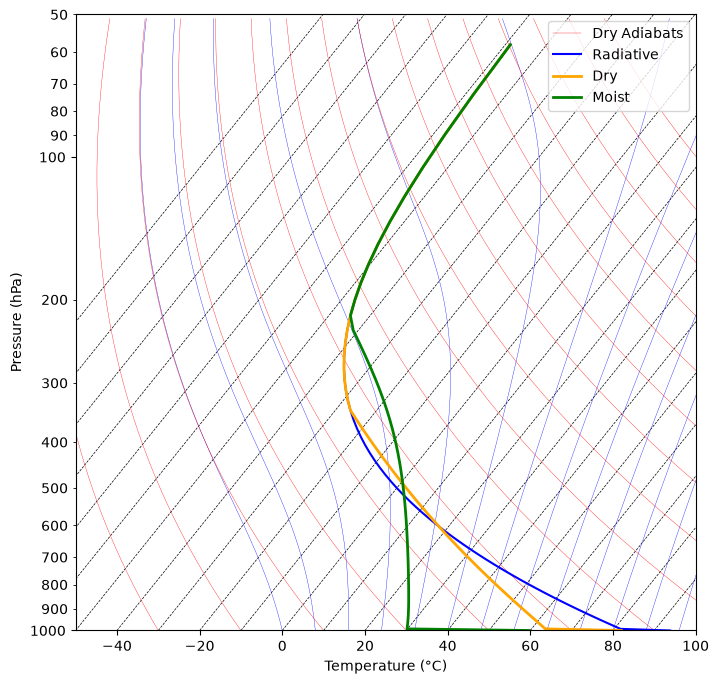

In [56]:
#plotting for temp vs log pressure first

#temperature vs log pressure
import importlib
import plotskewT
importlib.reload(plotskewT)

#Radiative
T_rad = history_save['radiative']['T'][-1] - 273.15
T_rad = np.insert(T_rad, 0, history_save['radiative']['T_surf'][-1] - 273.15)
#dry
T_dry = history_save['dry']['T'][-1] - 273.15
T_dry = np.insert(T_dry, 0, history_save['dry']['T_surf'][-1] - 273.15)
#moist
T_moist = history_save['moist']['T'][-1] - 273.15
T_moist = np.insert(T_moist, 0, history_save['moist']['T_surf'][-1] - 273.15)

#grab other plots


pres = grid['p_mid'] / 100 # pressure from last saved
pres = np.insert(pres, 0, 1000)
fig, ax = plotskewT.plotskewT(T_rad, pres)
ax.lines[-1].set_label('Radiative')

ax.plot(plotskewT.skewT(T_dry, pres), pres,
        color='orange', linewidth=2, label='Dry')

ax.plot(plotskewT.skewT(T_moist, pres), pres,
        color='green', linewidth=2, label='Moist')

ax.legend()
plt.show()


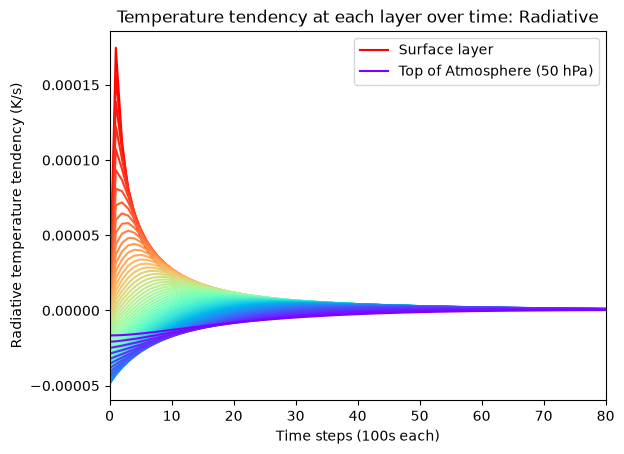

In [ ]:

tempchanges = np.asarray(history_save['radiative']['dTdt_rad'])


fig, ax = plt.subplots()
colors = plt.cm.rainbow_r(np.linspace(0, 1, tempchanges.shape[1]))
for level, color in enumerate(colors):
    label = 'Surface layer' if level == 0 else 'Top of Atmosphere (50 hPa)' if level == tempchanges.shape[1] - 1 else None
    ax.plot(tempchanges[:, level], color=color, label=label)
ax.set_xlim(0, 80)
ax.set_xlabel('Time steps (100s each)')
ax.set_ylabel('Radiative temperature tendency (K/s)')
ax.legend()
ax.set_title('Temperature tendency at each layer over time: Radiative')
plt.show()

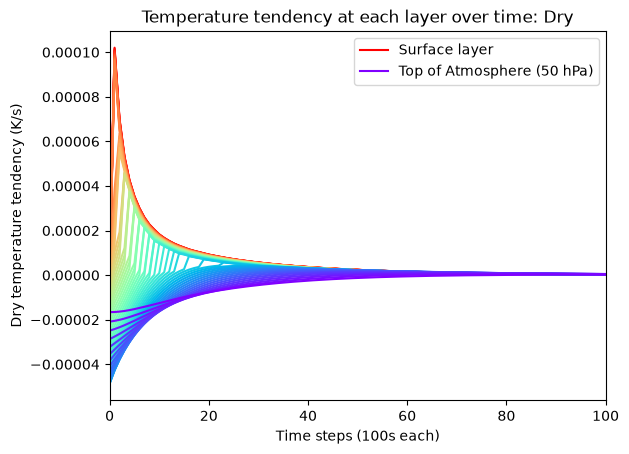

In [73]:

tempchanges1 = np.asarray(history_save['dry']['dTdt_conv'])
tempchanges11 = np.asarray(history_save['dry']['dTdt_rad'])

imbalance = tempchanges1 + tempchanges11

fig, ax = plt.subplots()
colors = plt.cm.rainbow_r(np.linspace(0, 1, imbalance.shape[1]))
for level, color in enumerate(colors):
    label = 'Surface layer' if level == 0 else 'Top of Atmosphere (50 hPa)' if level == imbalance.shape[1] - 1 else None
    ax.plot(imbalance[:, level], color=color, label=label)
ax.set_xlim(0, 100)
ax.set_xlabel('Time steps (100s each)')
ax.set_ylabel('Dry temperature tendency (K/s)')
ax.legend()
ax.set_title('Temperature tendency at each layer over time: Dry')
plt.show()

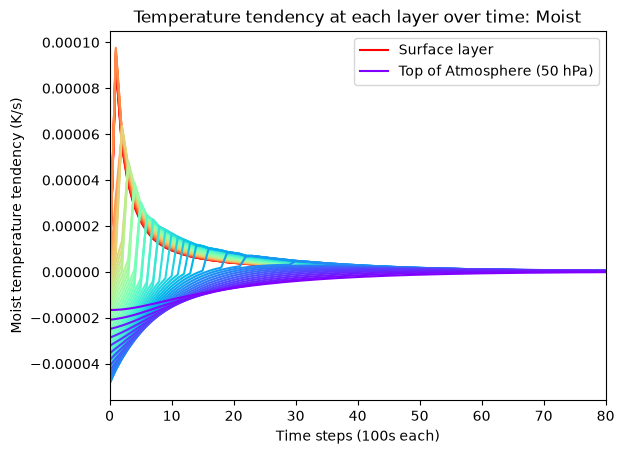

In [74]:
tempchanges3 = np.asarray(history_save['moist']['dTdt_conv'])
tempchanges33 = np.asarray(history_save['moist']['dTdt_rad'])
imbalance3 = tempchanges3 + tempchanges33

fig, ax = plt.subplots()
colors = plt.cm.rainbow_r(np.linspace(0, 1, imbalance3.shape[1]))
for level, color in enumerate(colors):
    label = 'Surface layer' if level == 0 else 'Top of Atmosphere (50 hPa)' if level == imbalance3.shape[1] - 1 else None
    ax.plot(imbalance3[:, level], color=color, label=label)
ax.set_xlim(0, 80)
ax.set_xlabel('Time steps (100s each)')
ax.set_ylabel('Moist temperature tendency (K/s)')
ax.legend()
ax.set_title('Temperature tendency at each layer over time: Moist')
plt.show()

3. In the pure radiative equilibrium, changes in air density with height first establish that a gradient in heat capacity must be present as a funciton of height. This means that as the surface receives heating, a balance will eventually be reached where the emissions and received radiation at each layer is approximately balanced. When this happens, the top of the atmosphere will be in radiative equilibrium. However, this does not mean that each other layer will technically be in equilibrium. In the dry adiabatic case, we allow convection to occur which is purely dry, following the dry adiabatic lapse rate (DALR). This essentially is another factor that must be taken into account when drawing the overall temperature profile, as this also redistributes energy to other layers via mixing. If the surface or other layers warm too fast via radiative processes, mixing redistributes some of the excess energy to higher layers. At the moist adiabatic lapse rate, latent heat released by condensation of water vapor further redistributes heat higher. The combined effect of the dry adiabatic lapse rate and latent heating makes the resulting equilibrium temperature lower on average as heat from lower levels gets transported up. Eventually, as the moist adiabtic lapse rate decreases with height (due to lower saturation mixing ratios of water), radiative equilibrium becomes the dominant process once again contributing to the temperature. 

4. In the first scenario, heat is not exchanged at all between layers. This means that the resulting balance is purely due to outgoing longwave radiation transferring from other layers. With no exchange of heat, a relatively steep lapse rate arises. The approach to equilibrium results from the surface absorbing significant radiation, heating up, re emitting this radiation as longwave to higher layers, and eventually reaching the top of the atmosphere. Once the top of the atmosphere's radiation balance is reached and all other layers slow down their rate of temperature change, equilibrium is reached. When dry convection is added, heat from lower levels gets transported upwards vertically. Because this is always happening as radiative equilibrium tries to take the lapse rate beyond dry adiabtic, significant mass exchange between levels will be ongoing as buoyant parcels rise. The effect of this is constant redistribution of heat in our profile, giving way to a more stable profile where temps near the surface are cooler, but temps aloft are warmer. With moist convection, latent heating must be taken into account. This produces a very similar effect as mass and heat are exchanged across layers. However, because the moist adiabatic lapse rate is a lower magnitude than that of the DALR, the profile stays even cooler closer to the surface, but much warmer aloft.

5. Initially, I wanted a unique approach to the convective adjustment to the model, but it did not end up working. I first thought that once a section goes beyond dry adiabatic, you could in theory manually set the lapse rate to be dry adiabatic and enforce this as a maximum. I wanted to work this as a top-down approach in order to account for the fact that the lapse rates should start much lower than convective lapse rates at that height. However, what I failed to account for was that manually setting the lapse rate essentially was a constant heat sink. Heat was never retianed in the system, but was simply lost as this method tried to make sense of it. I realized that the loss of heat was generating profiles that were substantially colder than my current results. In terms of implementing new components directly, I implemented the plots that plotted every layer's change in change in temperature. with time. I found this interesting to color code each layer. The figure itself definitely has several lines, but the rainbow colors allow us to see well how the profiles differ across varying pressure levels.   